In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import PATH_INTERIM, PATH_PROCESSED
from ml_atmospheric_emission.dataset import load_interim
from ml_atmospheric_emission.features import create_datetime_columns,create_future_targets,create_target
from ml_atmospheric_emission.modeling.train import train_model_experiment
from ml_atmospheric_emission.util import linear_graph

In [35]:
qtd_deslocamento = 72  #ate 2 horas no futuro
ds = load_interim()
ds = create_datetime_columns(ds)
ds = create_target(ds)
ds = create_future_targets(ds, qtd_deslocamento)

ds.columns

Index(['Data', 'nn_score_smog', 'int_sd', 'int_med', '306-AIT-004-2',
       '306-AIT-004-5', '306FE002-AI001-R', '406-AI-004-2', '406-AI-004-4',
       '406-AIT-001', 'Mes', 'Hora', 'Minuto', 'Dia_Semana', 'y', 'y_5',
       'y_10', 'y_15', 'y_20', 'y_25', 'y_30', 'y_35', 'y_40', 'y_45', 'y_50',
       'y_55', 'y_60', 'y_65', 'y_70', 'y_75', 'y_80', 'y_85', 'y_90', 'y_95',
       'y_100', 'y_105', 'y_110', 'y_115', 'y_120', 'y_125', 'y_130', 'y_135',
       'y_140', 'y_145', 'y_150', 'y_155', 'y_160', 'y_165', 'y_170', 'y_175',
       'y_180', 'y_185', 'y_190', 'y_195', 'y_200', 'y_205', 'y_210', 'y_215',
       'y_220', 'y_225', 'y_230', 'y_235', 'y_240', 'y_245', 'y_250', 'y_255',
       'y_260', 'y_265', 'y_270', 'y_275', 'y_280', 'y_285', 'y_290', 'y_295',
       'y_300', 'y_305', 'y_310', 'y_315', 'y_320', 'y_325', 'y_330', 'y_335',
       'y_340', 'y_345', 'y_350', 'y_355', 'y_360'],
      dtype='str')

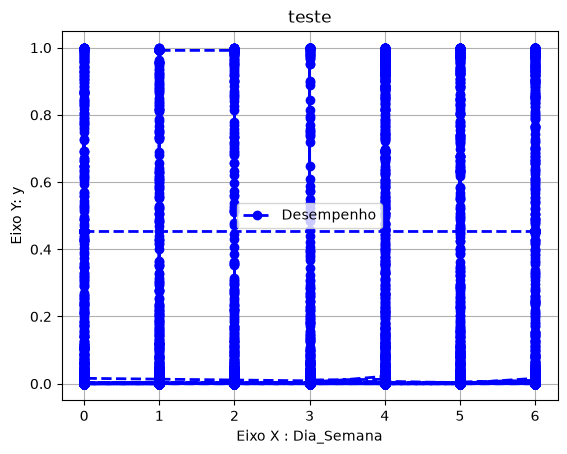

In [36]:
linear_graph(ds['Dia_Semana'],ds['y'],'teste')

In [17]:
qtd_deslocamento = 72  #ate 2 horas no futuro
ds = load_interim()
ds = create_datetime_columns(ds)
ds = create_target(ds)
ds = create_future_targets(ds, qtd_deslocamento)
print(ds.columns)

train_model_experiment(ds, 'y')
for deslocamento_ in range(1, qtd_deslocamento + 1):
    train_model_experiment(ds, f'y_{deslocamento_*5}', gap=deslocamento_)

Index(['Data', 'nn_score_smog', 'int_sd', 'int_med', '306-AIT-004-2',
       '306-AIT-004-5', '306FE002-AI001-R', '406-AI-004-2', '406-AI-004-4',
       '406-AIT-001', 'Mes', 'Hora', 'Minuto', 'Dia_Semana', 'y', 'y_5',
       'y_10', 'y_15', 'y_20', 'y_25', 'y_30', 'y_35', 'y_40', 'y_45', 'y_50',
       'y_55', 'y_60', 'y_65', 'y_70', 'y_75', 'y_80', 'y_85', 'y_90', 'y_95',
       'y_100', 'y_105', 'y_110', 'y_115', 'y_120', 'y_125', 'y_130', 'y_135',
       'y_140', 'y_145', 'y_150', 'y_155', 'y_160', 'y_165', 'y_170', 'y_175',
       'y_180', 'y_185', 'y_190', 'y_195', 'y_200', 'y_205', 'y_210', 'y_215',
       'y_220', 'y_225', 'y_230', 'y_235', 'y_240', 'y_245', 'y_250', 'y_255',
       'y_260', 'y_265', 'y_270', 'y_275', 'y_280', 'y_285', 'y_290', 'y_295',
       'y_300', 'y_305', 'y_310', 'y_315', 'y_320', 'y_325', 'y_330', 'y_335',
       'y_340', 'y_345', 'y_350', 'y_355', 'y_360'],
      dtype='str')
Modelo: y
f1_score_train: 0.507
f1_score_test: 0.337
recall_train: 0.955
reca

KeyboardInterrupt: 

In [ ]:
ds.to_csv(PATH_PROCESSED, index=False)
ds.info()